# EDA: цены Day-Ahead, Венгрия

Данные от куратора, в репозиторий не входят (лежат локально в `data/raw/`, см. `.gitignore`).
Часовой ряд 01.01.2024–31.12.2025, timestamp в UTC, загрузка через `dayahead.data.load_raw` переводит в Europe/Budapest.

Колонки: цель `price_eur_mwh` и шесть прогнозов на сутки вперёд: спрос, солнце, ветер, атом, сальдо обмена (МВт·ч), температура (°C).

Три вопроса этапа: сезонность, выбросы, связи признаков с ценой.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from statsmodels.tsa.stattools import acf

from dayahead.data import load_raw

sns.set_theme(style="whitegrid")

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
DATA_PATH = ROOT / "data" / "raw" / "hu_dayahead_2024_2025.csv"
TARGET = "price_eur_mwh"

df = load_raw(DATA_PATH)
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 17544 entries, 2024-01-01 00:00:00+01:00 to 2025-12-31 23:00:00+01:00
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   price_eur_mwh              17544 non-null  float64
 1   demand_forecast_mwh        17544 non-null  float64
 2   solar_forecast_mwh         17544 non-null  float64
 3   net_exchange_forecast_mwh  17544 non-null  float64
 4   wind_forecast_mwh          17544 non-null  float64
 5   nuclear_forecast_mwh       17544 non-null  float64
 6   temperature_forecast_c     17544 non-null  float64
dtypes: float64(7)
memory usage: 1.1 MB


In [3]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
price_eur_mwh,17544.0,104.7,73.1,-210.0,72.8,97.7,126.4,999.0
demand_forecast_mwh,17544.0,4932.7,849.9,2303.4,4290.3,4860.8,5504.7,7442.8
solar_forecast_mwh,17544.0,709.5,1021.8,0.0,0.0,34.9,1266.2,4329.1
net_exchange_forecast_mwh,17544.0,-1096.1,1332.2,-5365.3,-2064.2,-1299.8,-219.2,3819.9
wind_forecast_mwh,17544.0,66.3,61.7,0.6,16.5,47.1,97.5,291.8
nuclear_forecast_mwh,17544.0,1740.1,222.6,1372.2,1440.0,1900.0,1900.0,1949.5
temperature_forecast_c,17544.0,12.6,9.4,-7.0,4.9,12.0,20.0,35.9


In [4]:
step = df.index.to_series().diff().dropna().dt.total_seconds()
print("индекс монотонный:", df.index.is_monotonic_increasing)
print("дубликатов времени:", df.index.duplicated().sum())
print("шаг ровно 1 ч во всех строках:", bool((step == 3600).all()))
print("часов в сутках при переходе на летнее/зимнее время:",
      sorted(df.groupby(df.index.date).size().unique().tolist()))

индекс монотонный: True
дубликатов времени: 0
шаг ровно 1 ч во всех строках: True
часов в сутках при переходе на летнее/зимнее время: [23, 24, 25]


Пропусков и дыр нет, шаг ровно час. Сутки с 23 и 25 часами это переход на летнее/зимнее время, в локальном времени он учтён.

In [5]:
eda = df.copy()
eda["hour"] = eda.index.hour
eda["dow"] = eda.index.dayofweek
eda["month"] = eda.index.month
eda["year"] = eda.index.year
eda["is_weekend"] = eda["dow"] >= 5
eda["residual_load"] = (
    eda["demand_forecast_mwh"]
    - eda["solar_forecast_mwh"]
    - eda["wind_forecast_mwh"]
    - eda["nuclear_forecast_mwh"]
)
price = eda[TARGET]

## 1. Сезонность

### Суточный профиль

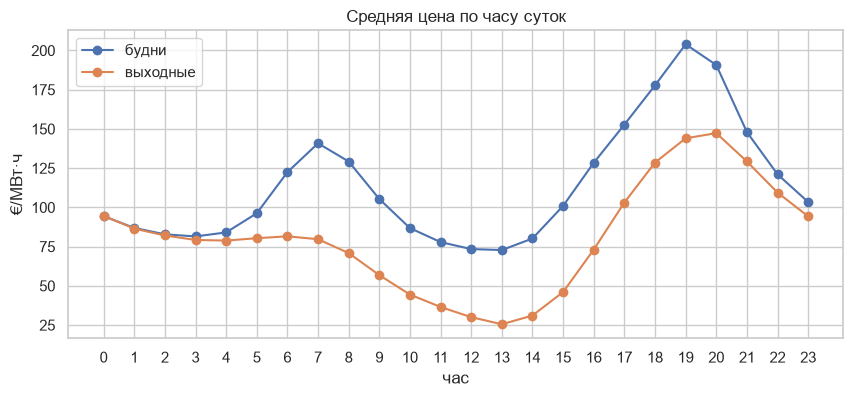

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
for wk, label in [(False, "будни"), (True, "выходные")]:
    price[eda["is_weekend"] == wk].groupby(eda["hour"]).mean().plot(ax=ax, marker="o", label=label)
ax.set(title="Средняя цена по часу суток", xlabel="час", ylabel="€/МВт·ч", xticks=range(24))
ax.legend();

Два пика: утренний около 7 ч и вечерний 18–20 ч, вечерний в полтора раза выше. Днём в 12–13 ч провал ниже ночного уровня: это солнце. В выходные профиль той же формы, но примерно на 30 €/МВт·ч ниже.

### Час х месяц

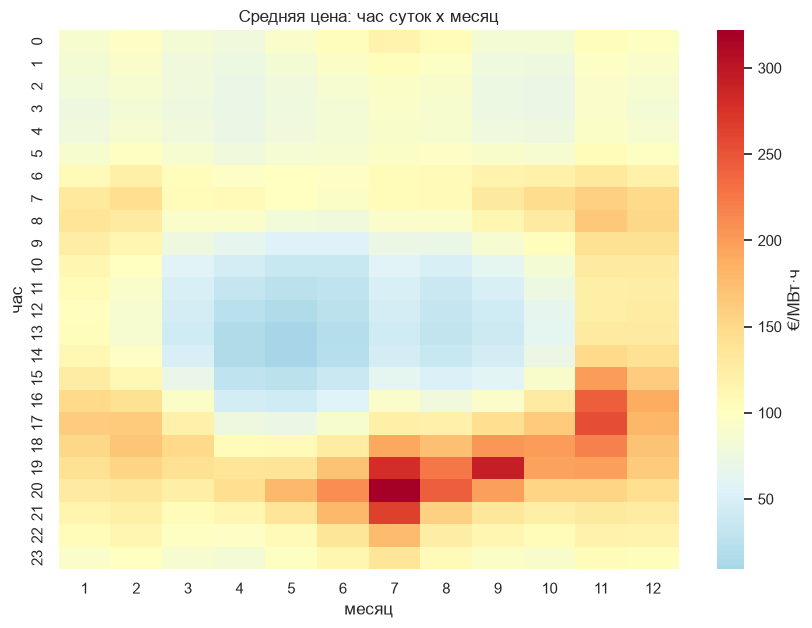

In [7]:
pivot = price.groupby([eda["hour"], eda["month"]]).mean().unstack()
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(pivot, cmap="RdYlBu_r", center=100, ax=ax, cbar_kws={"label": "€/МВт·ч"})
ax.set(title="Средняя цена: час суток х месяц", xlabel="месяц", ylabel="час");

Дневной провал есть только с марта по сентябрь и углубляется к апрелю–маю. Зимой провала нет, выражены оба пика. Самые дорогие часы: вечера ноября–декабря. Суточный профиль зависит от сезона.

### Недельная и годовая динамика

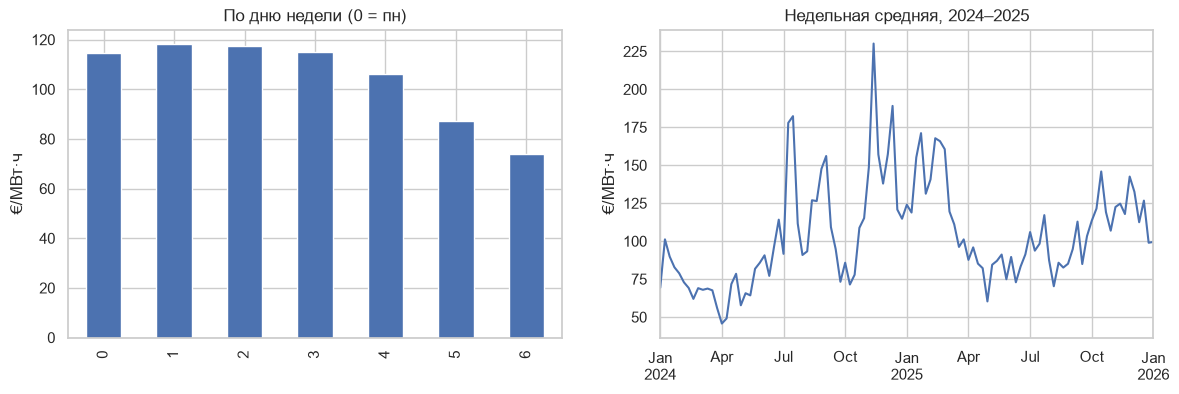

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
price.groupby(eda["dow"]).mean().plot(kind="bar", ax=axes[0], title="По дню недели (0 = пн)")
price.resample("W").mean().plot(ax=axes[1], title="Недельная средняя, 2024–2025")
axes[0].set(xlabel="", ylabel="€/МВт·ч")
axes[1].set(xlabel="", ylabel="€/МВт·ч");

In [9]:
price.groupby([eda["year"], eda["month"]]).mean().unstack(0).round(1)

year,2024,2025
month,,
1,85.7,140.2
2,69.4,158.9
3,65.1,109.0
4,62.0,85.5
5,72.2,80.9
6,91.7,84.1
7,135.5,102.6
8,120.8,80.5
9,106.1,101.9


Воскресенье самый дешёвый день, суббота близко. Годовой цикл: дорогие зима и июль, дешёвые апрель–май. 2025 в среднем дороже 2024 (108 против 101 €/МВт·ч), но различия по месяцам больше, чем между годами, так что тренд слабый.

### Автокорреляция

{1: 0.88, 12: 0.22, 24: 0.78, 48: 0.64, 168: 0.69, 336: 0.57}


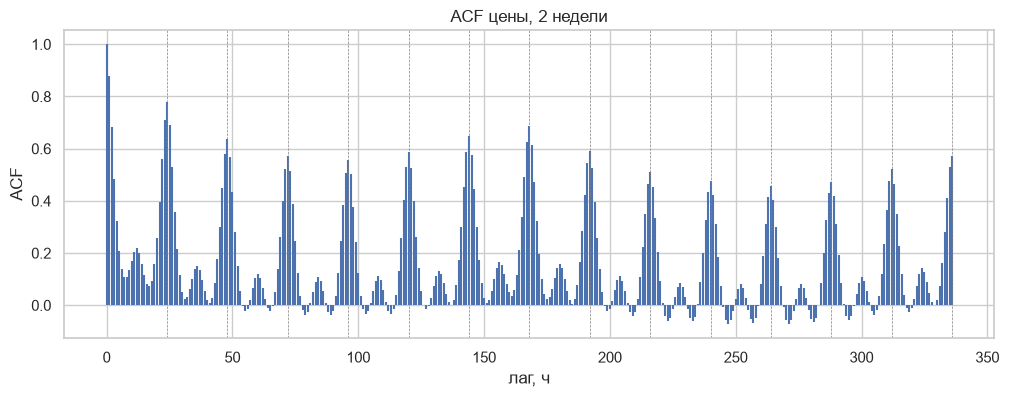

In [10]:
lags = 24 * 14
ac = acf(price, nlags=lags)
fig, ax = plt.subplots(figsize=(12, 4))
ax.stem(range(lags + 1), ac, markerfmt=" ", basefmt=" ")
for k in range(24, lags + 1, 24):
    ax.axvline(k, color="grey", lw=0.5, ls="--")
ax.set(title="ACF цены, 2 недели", xlabel="лаг, ч", ylabel="ACF");
print({k: round(float(ac[k]), 2) for k in [1, 12, 24, 48, 168, 336]})

Пики на кратных 24 ч, самый высокий из дальних на 168 ч (0.69 против 0.64 на 48 ч): недельная сезонность сильнее, чем кажется по дням недели. Лаги 24 и 168 ч это естественные признаки для модели.

## 2. Выбросы

### Распределение цены

часов с ценой <= 0: 650, > 300: 311, из 17544


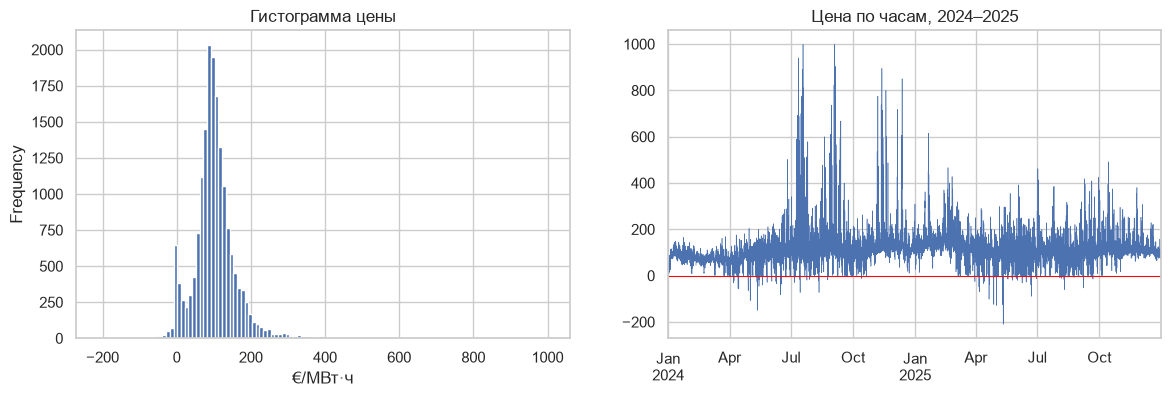

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
price.plot(kind="hist", bins=120, ax=axes[0], title="Гистограмма цены")
axes[0].set(xlabel="€/МВт·ч")
price.plot(ax=axes[1], lw=0.4, title="Цена по часам, 2024–2025")
axes[1].axhline(0, color="red", lw=0.7)
axes[1].set(xlabel="");

neg = price <= 0
peak = price > 300
print(f"часов с ценой <= 0: {neg.sum()}, > 300: {peak.sum()}, из {len(price)}")

### Когда случаются отрицательные цены и пики

доля выходных среди часов с ценой <= 0: 0.81
средний прогноз солнца при цене <= 0: 2696 против в среднем 710


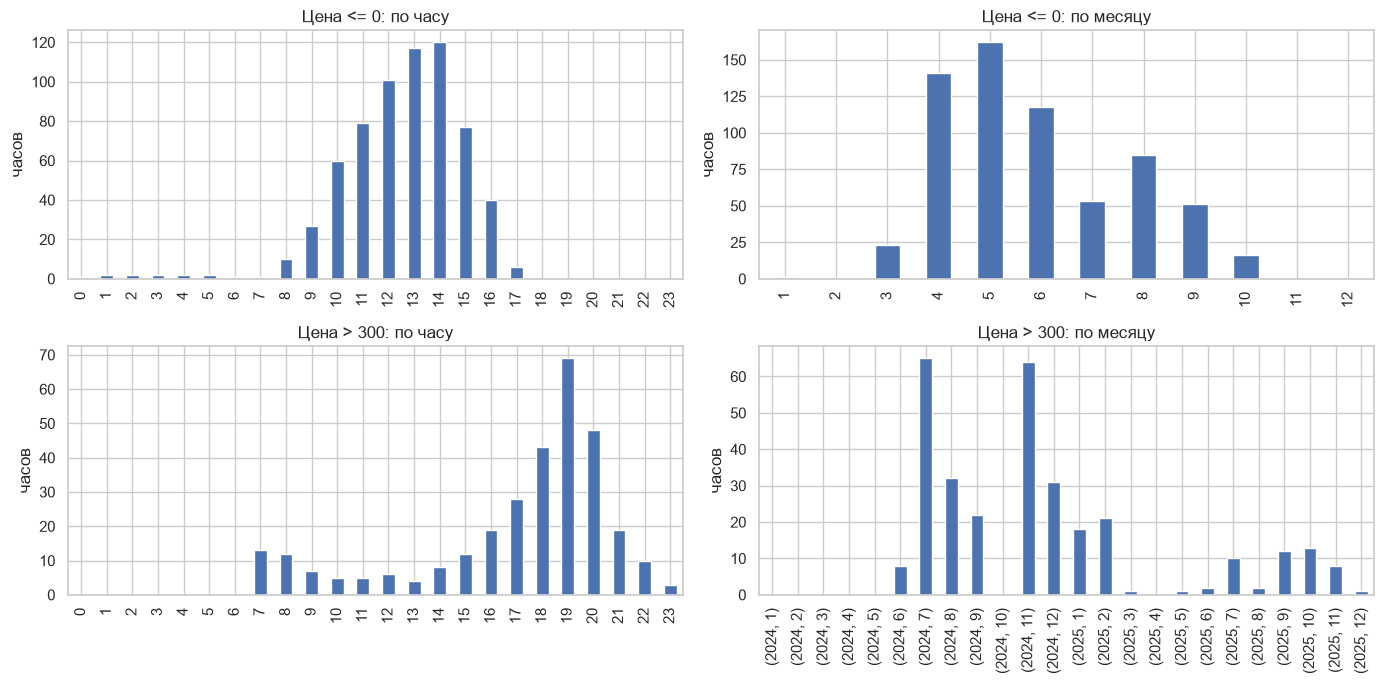

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
neg.groupby(eda["hour"]).sum().plot(kind="bar", ax=axes[0, 0], title="Цена <= 0: по часу")
neg.groupby(eda["month"]).sum().plot(kind="bar", ax=axes[0, 1], title="Цена <= 0: по месяцу")
peak.groupby(eda["hour"]).sum().plot(kind="bar", ax=axes[1, 0], title="Цена > 300: по часу")
peak.groupby([eda["year"], eda["month"]]).sum().plot(kind="bar", ax=axes[1, 1], title="Цена > 300: по месяцу")
for ax in axes.ravel():
    ax.set(xlabel="", ylabel="часов")
plt.tight_layout()

print("доля выходных среди часов с ценой <= 0:", round(eda.loc[neg, "is_weekend"].mean(), 2))
print("средний прогноз солнца при цене <= 0:", round(eda.loc[neg, "solar_forecast_mwh"].mean()),
      "против в среднем", round(eda["solar_forecast_mwh"].mean()))

Отрицательные и нулевые цены: 650 часов, почти все в 9–17 ч с апреля по сентябрь, 81% в выходные. Это солнечные полдни с низким спросом, а не ошибки данных. Пики выше 300 €: 311 часов, в основном вечера 17–21 ч, сильно сгруппированы: июль и ноябрь 2024 дают почти половину. В 2025 пиков заметно меньше.

Обрезать нельзя, это целевые режимы; метрику считать отдельно по хвостам.

## 3. Взаимосвязи

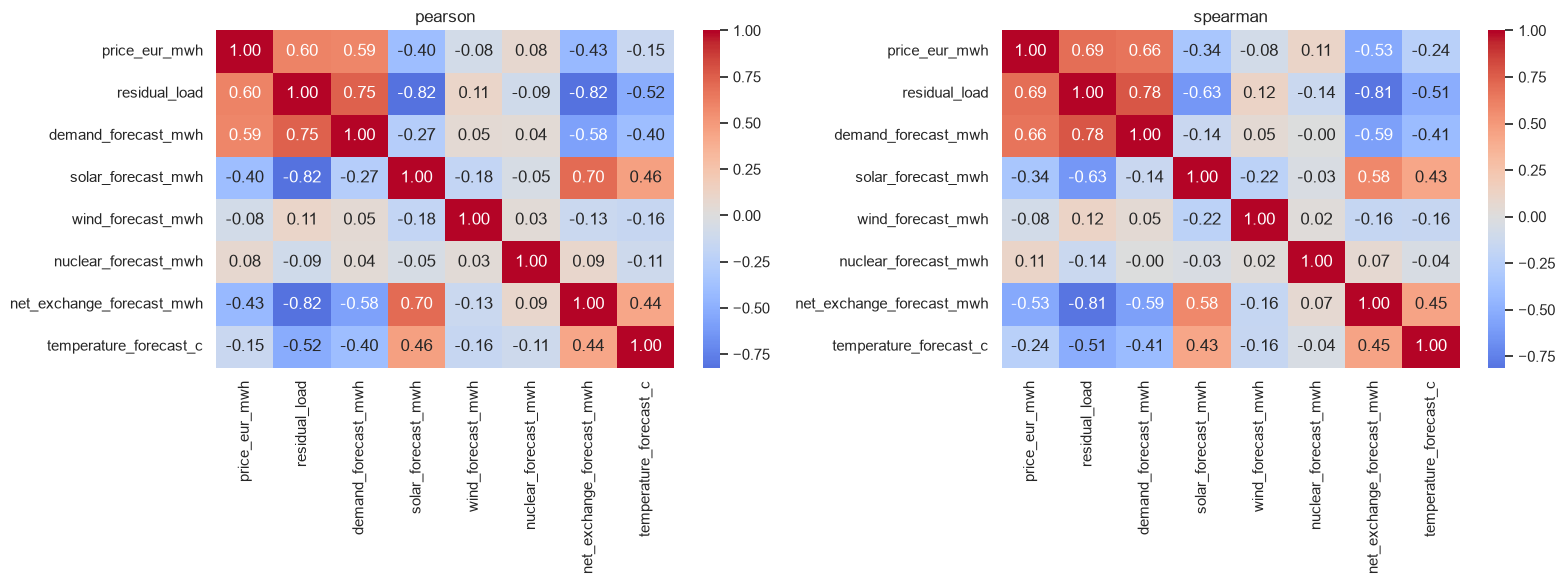

In [13]:
cols = [TARGET, "residual_load", "demand_forecast_mwh", "solar_forecast_mwh", "wind_forecast_mwh",
        "nuclear_forecast_mwh", "net_exchange_forecast_mwh", "temperature_forecast_c"]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(eda[cols].corr(method), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
    ax.set_title(method)
plt.tight_layout()

Сильнее всего с ценой связаны residual load (Spearman 0.69) и спрос (0.66), затем сальдо обмена (−0.53: чем больше импорт, тем дороже) и солнце (−0.34). Ветер и атом с ценой почти не связаны: ветра в Венгрии мало, атом почти константа. Температура слабо отрицательная: холод поднимает спрос, но летняя жара тоже.

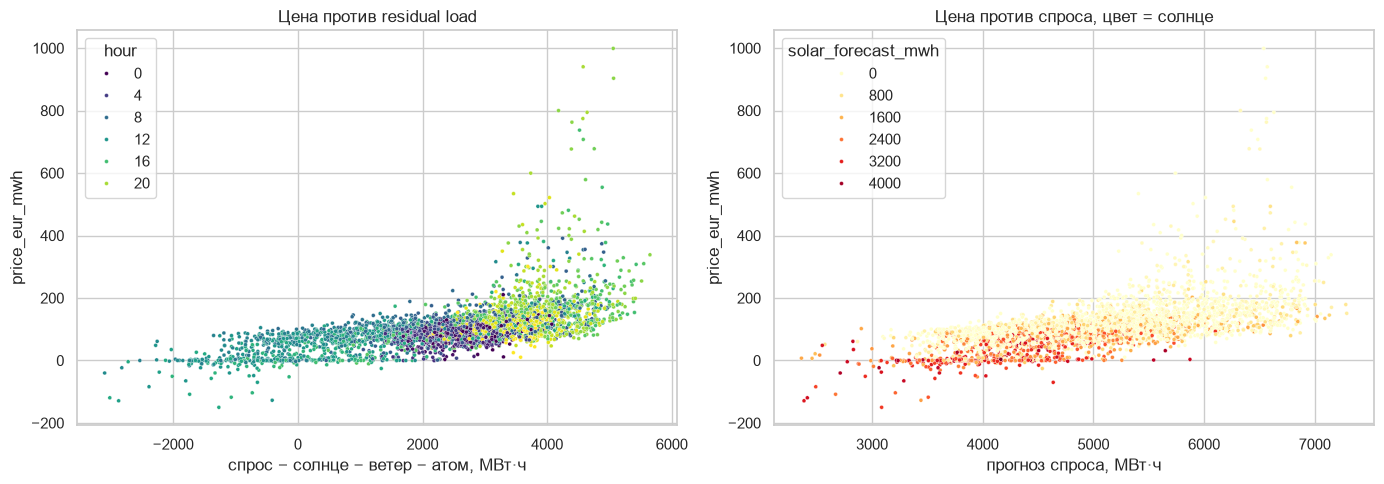

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sample = eda.sample(4000, random_state=0)
sns.scatterplot(data=sample, x="residual_load", y=TARGET, hue="hour", palette="viridis", s=8, ax=axes[0])
axes[0].set(title="Цена против residual load", xlabel="спрос − солнце − ветер − атом, МВт·ч")
sns.scatterplot(data=sample, x="demand_forecast_mwh", y=TARGET, hue="solar_forecast_mwh",
                palette="YlOrRd", s=8, ax=axes[1])
axes[1].set(title="Цена против спроса, цвет = солнце", xlabel="прогноз спроса, МВт·ч")
plt.tight_layout()

Связь цены с residual load выпуклая, похожа на merit-order кривую: при низкой остаточной нагрузке цена около нуля, при высокой растёт быстрее линейного. Линейной модели тут не хватит, нужны либо нелинейные признаки, либо деревья. На правом графике видно, что при одном и том же спросе цена заметно ниже, когда солнца много.

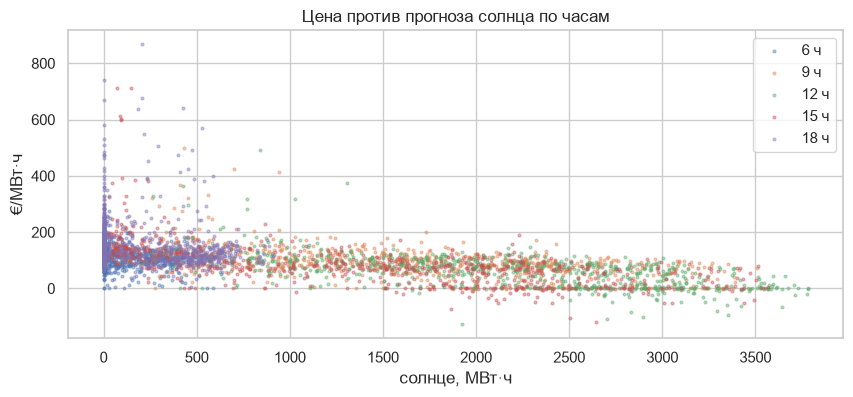

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
for h in [6, 9, 12, 15, 18]:
    sub = eda[eda["hour"] == h]
    ax.scatter(sub["solar_forecast_mwh"], sub[TARGET], s=4, alpha=0.4, label=f"{h} ч")
ax.set(title="Цена против прогноза солнца по часам", xlabel="солнце, МВт·ч", ylabel="€/МВт·ч")
ax.legend();

В полдень корреляция цены с солнцем −0.6, при больших значениях солнца цена уходит в ноль и ниже. В 18 ч солнца почти нет и связь исчезает. Это подтверждает: эффект солнца зависит от часа, модели нужно взаимодействие «час × солнце» или просто residual load.

## 4. Атом: остановы блоков Пакша

часов с генерацией ниже 1800: 6290 (36%)
средняя цена при остановах и в норме: 96.9 109.0


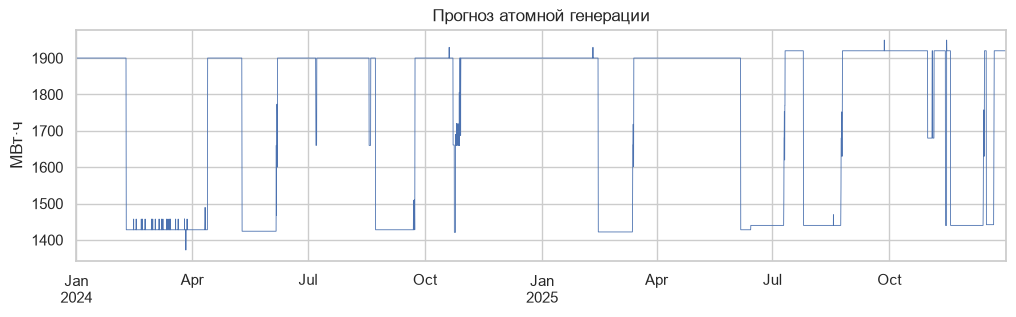

In [16]:
fig, ax = plt.subplots(figsize=(12, 3))
eda["nuclear_forecast_mwh"].plot(ax=ax, lw=0.6, title="Прогноз атомной генерации")
ax.set(xlabel="", ylabel="МВт·ч");

low = eda["nuclear_forecast_mwh"] < 1800
print("часов с генерацией ниже 1800:", low.sum(), f"({low.mean():.0%})")
print("средняя цена при остановах и в норме:",
      round(price[low].mean(), 1), round(price[~low].mean(), 1))

Нормальный уровень около 1900 МВт·ч, при остановах одного блока падает до 1400. Остановов 10–12 в год длиной от нескольких дней до двух месяцев, это 36% часов. Корреляция с ценой низкая, но режим известен заранее и входит в residual load.

## Выводы EDA

1. **Сезонность трёхуровневая**: суточная (два пика, дневной провал), недельная (выходные на 30 € дешевле, ACF на 168 ч выше, чем на 48 ч), годовая (дорогие зима и июль, дешёвые апрель–май). Суточный профиль меняется по сезону, поэтому календарные признаки должны работать в связке.
2. **Выбросы это не шум**: отрицательные цены — солнечные полдни выходных весной и летом, пики — зимние и июльские вечера, сгруппированные по месяцам. Их надо прогнозировать, а не обрезать.
3. **Главный драйвер — residual load**, связь нелинейная, выпуклая. Ветер и атом сами по себе мало информативны, но входят в residual load; остановы Пакша известны заранее.
4. **Для моделей**: лаги цены 24 и 168 ч, residual load, календарь по локальному времени, метрики MAE и RMSE отдельно по хвостам.